## MTL Trajet: 11 Three-user Weekday Periodicity (Flag 11)

### Dataset Overview
Three users visit a shared riverside-recreation hub on successive weekdays and then follow different driving or shopping routines. Official land-use labels follow the unchanged endpoints; Unmapped denotes an endpoint outside reference polygons.

The notebook exposes a primary table and a supporting table (`trajectory_points.csv`).

Goal: Find same points and differences of three users based on given trajectories within five weekdays.

Role: Urban mobility analyst


Category: Three-user riverside-hub periodicity, café repetition, shopping-area coordination, and driving behaviour

### Your Objective
Use the provided tables and visual evidence to answer the questions below and summarize the observed trajectory patterns.


## Import Necessary Libraries

This cell loads the data-analysis and visualization libraries used by the questions below.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, SVG, display
points=pd.read_csv('trajectory_points.csv')


## Load Dataset

The primary table is loaded into `df`; when available, the supporting trajectory or driver table is loaded into `user_df`.

In [ ]:
dataset_path = "trajectories.csv"
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv(dataset_path)

In [ ]:
user_dataset_path = "trajectory_points.csv"
user_df = pd.read_csv(user_dataset_path)

### **Question 1**: For each user, are arrivals at the same riverside-recreation hub stable across the five weekdays despite differing origins?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

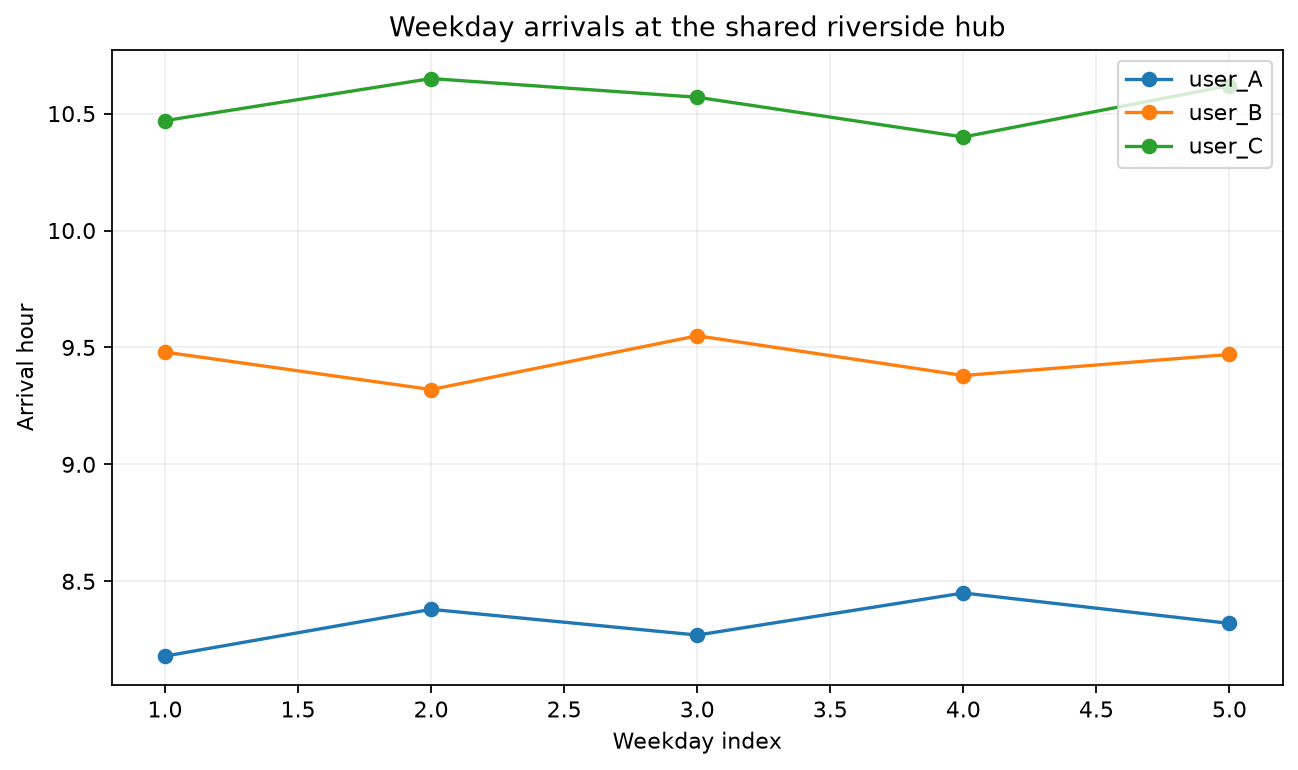

In [ ]:
import pandas as pd
import numpy as np
from pathlib import Path
df = pd.read_csv(dataset_path)
points = pd.read_csv(Path(dataset_path).with_name('trajectory_points.csv'))
hub=df[df.trip_stage.eq('to_shared_hub')]; print(hub.groupby('user_id').arrival_hour.agg(['min','max','mean','std'])); print(hub.destination_land_use.value_counts())

from IPython.display import Image, display
display(Image(filename='visualizations/weekday_periodicity_repeated_destinations.png'))


#### Generate JSON Description for the Insight

**Insight difficulty: High (5 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "shared_mixte_hub_periodicity",
  "insight": "Weekday arrival times at the shared riverside-recreation hub differ across users, while remaining relatively consistent for each individual.",
  "insight_type": "group_comparison",
  "plot": {
    "plot_type": "trajectory_comparison",
    "title": "Shared Riverside Hub and Weekday Periodicity",
    "description": "Recomputed from the delivered fixed GPS coordinates and the archived official PUM2050 Affectatio polygons; Unmapped denotes no containing polygon.",
    "file": "visualizations/weekday_periodicity_repeated_destinations.png"
  },
  "question": "For each user, are arrivals at the same riverside-recreation hub stable across the five weekdays despite differing origins?",
  "code": "import pandas as pd\nimport numpy as np\nfrom pathlib import Path\ndf = pd.read_csv(dataset_path)\npoints = pd.read_csv(Path(dataset_path).with_name('trajectory_points.csv'))\nhub=df[df.trip_stage.eq('to_shared_hub')]; print(hub.groupby('user_id').arrival_hour.agg(['min','max','mean','std'])); print(hub.destination_land_use.value_counts())\n",
  "evidence": "All 15 hub endpoints occupy the same GPS location, mapped as Récréation et accès aux rives. The arrival windows remain distinct across users.",
  "insight_value": {
    "user_A": {
      "min": 8.18,
      "max": 8.45,
      "mean": 8.32,
      "std": 0.10319883720275111
    },
    "user_B": {
      "min": 9.32,
      "max": 9.55,
      "mean": 9.440000000000001,
      "std": 0.09027735042633894
    },
    "user_C": {
      "min": 10.4,
      "max": 10.65,
      "mean": 10.542,
      "std": 0.1047377677822092
    }
  },
  "difficulty_level": 5,
  "difficulty_label": "high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "user_id",
    "trajectory_timestamp",
    "trajectory_id",
    "gps_position",
    "land_use_reference"
  ]
}

### **Question 2**: From the shared riverside-recreation hub, how do User A's café trip and B/C shopping trips differ in mode and destination pattern?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

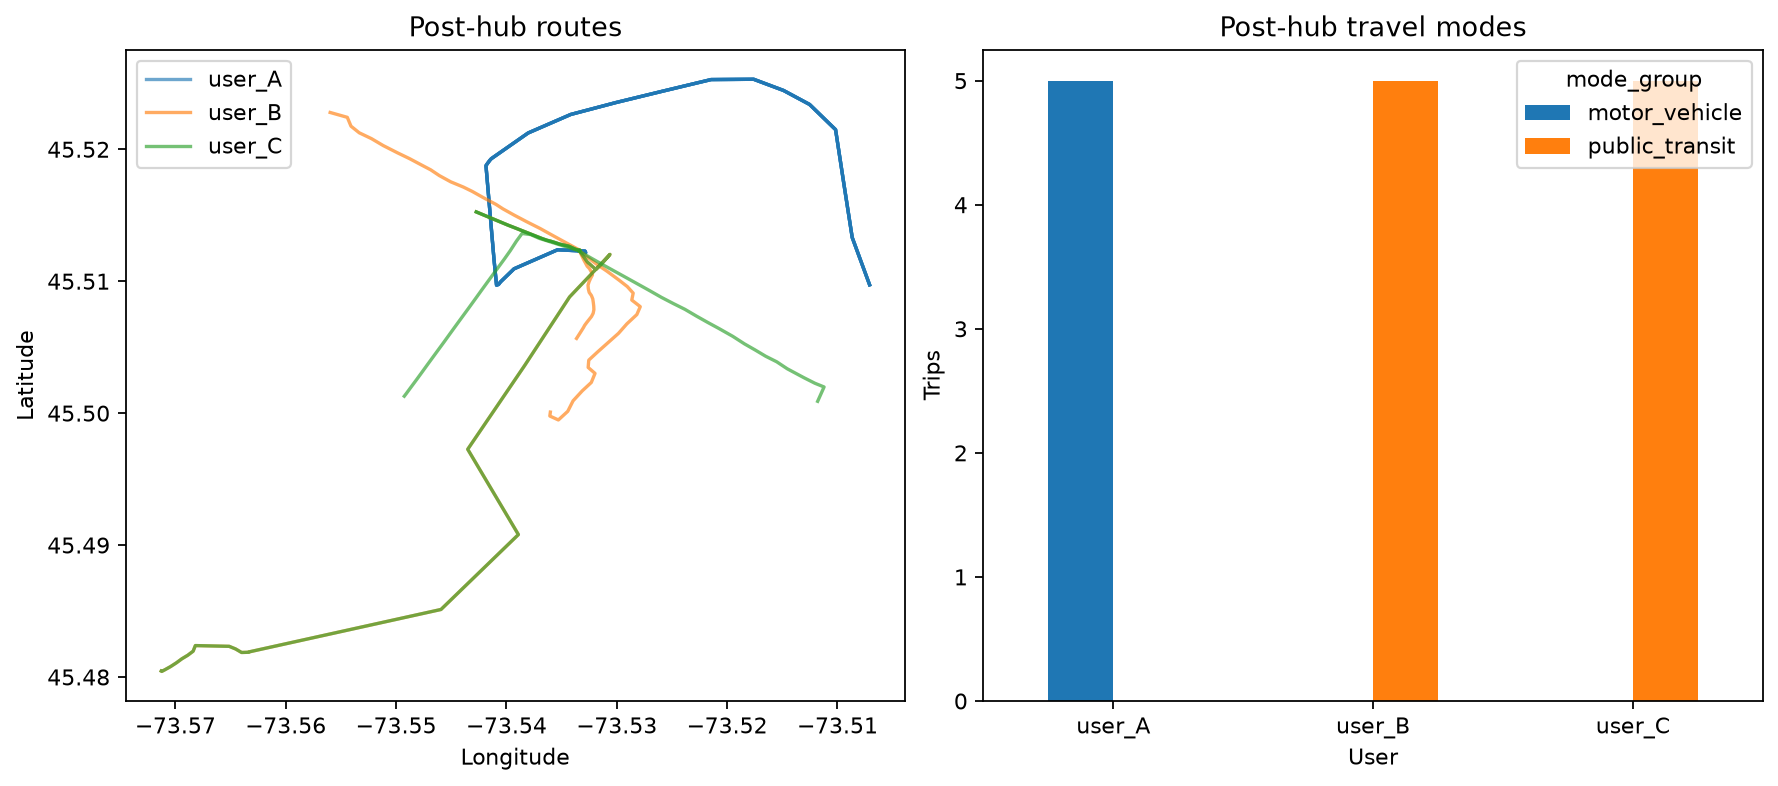

In [ ]:
import pandas as pd
import numpy as np
from pathlib import Path
df = pd.read_csv(dataset_path)
points = pd.read_csv(Path(dataset_path).with_name('trajectory_points.csv'))
follow=df[df.purpose_group.isin(['cafe','shopping'])]; print(pd.crosstab(follow.user_id,follow.mode_group)); print(follow.groupby(['weekday','destination_id']).user_id.apply(list))

from IPython.display import Image, display
display(Image(filename='visualizations/user_mode_and_shopping_destinations.png'))


#### Generate JSON Description for the Insight

**Insight difficulty: Very High (7 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "shared_hub_cafe_shopping_destination",
  "insight": "After spending several hours at the shared hub, User A follows a fixed driving routine, while Users B and C show more variable public-transit shopping patterns.",
  "insight_type": "group_comparison",
  "plot": {
    "plot_type": "trajectory_comparison",
    "title": "User A Café and B/C Shopping from the Shared Hub",
    "description": "Recomputed from the delivered fixed GPS coordinates and the archived official PUM2050 Affectatio polygons; Unmapped denotes no containing polygon.",
    "file": "visualizations/user_mode_and_shopping_destinations.png"
  },
  "question": "From the shared riverside-recreation hub, how do User A's café trip and B/C shopping trips differ in mode and destination pattern?",
  "code": "import pandas as pd\nimport numpy as np\nfrom pathlib import Path\ndf = pd.read_csv(dataset_path)\npoints = pd.read_csv(Path(dataset_path).with_name('trajectory_points.csv'))\nfollow=df[df.purpose_group.isin(['cafe','shopping'])]; print(pd.crosstab(follow.user_id,follow.mode_group)); print(follow.groupby(['weekday','destination_id']).user_id.apply(list))\n",
  "evidence": "The hub is a riverside-recreation location. Follow-up destination identities are canonical groups of identical endpoint coordinates; endpoints outside the supplied polygons have Unmapped land use.",
  "difficulty_level": 7,
  "difficulty_label": "very high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "user_id",
    "trajectory_timestamp",
    "trajectory_id",
    "gps_position",
    "land_use_reference",
    "transport_mode",
    "trip_purpose"
  ]
}

### **Question 3**: Across users and destinations, how similar are motor-vehicle speed profiles, and do the routes share a riverside context?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

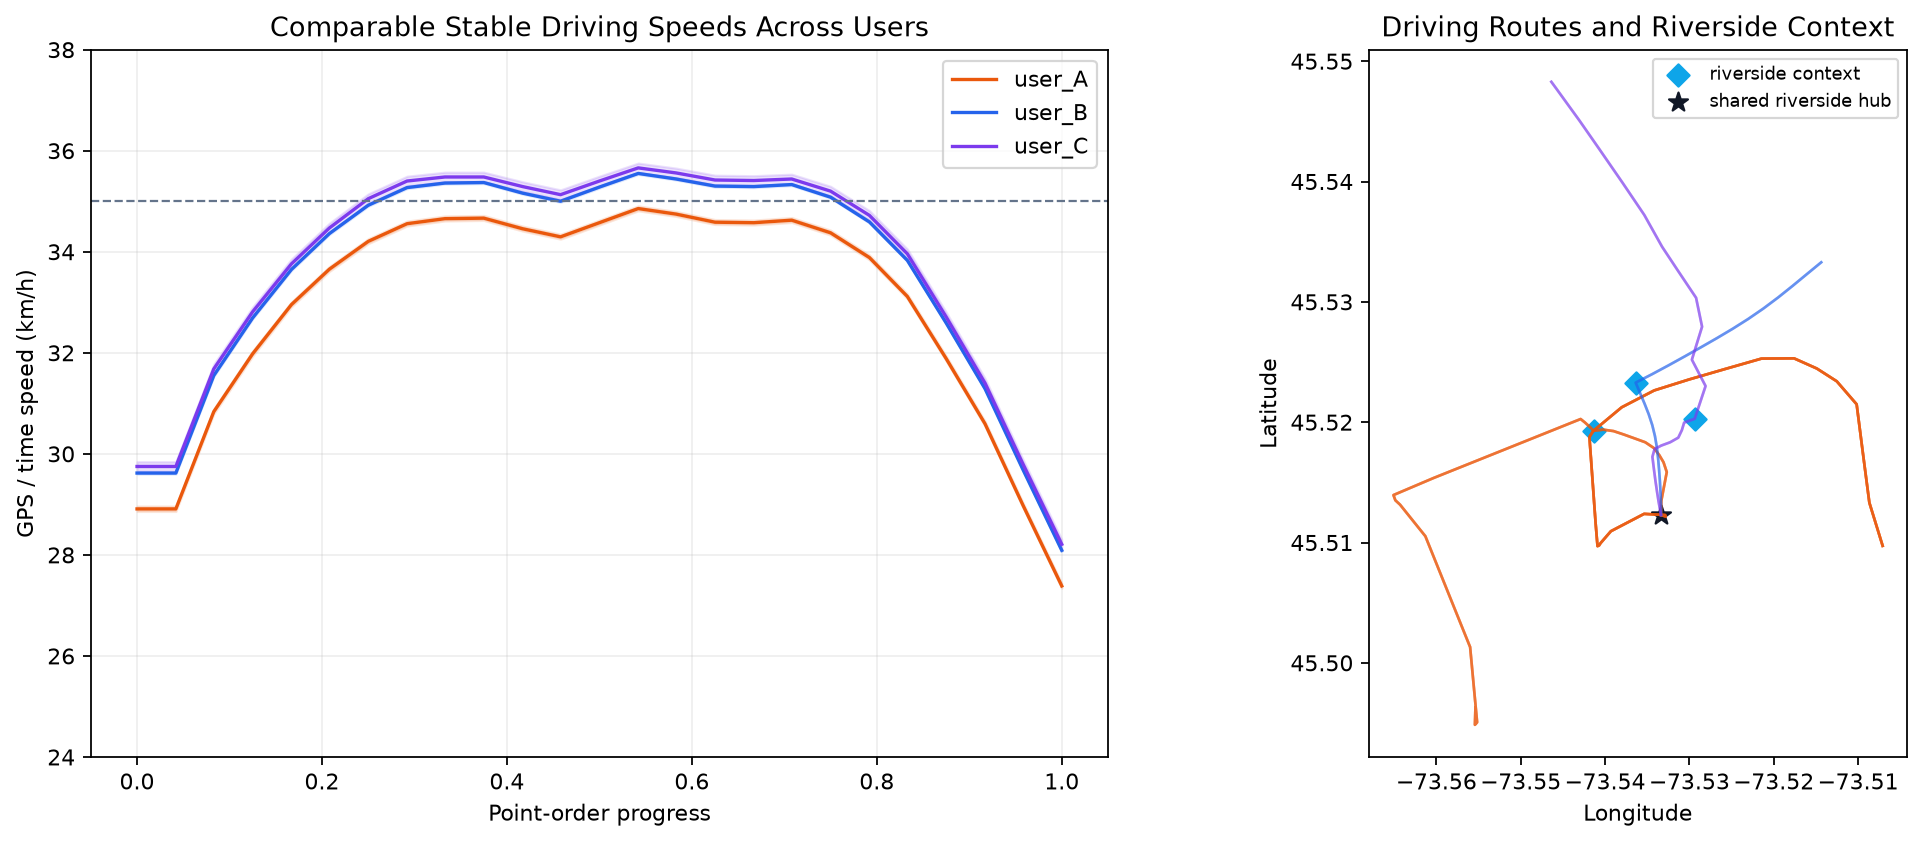

In [ ]:
df[df.mode_group.eq('motor_vehicle')].groupby('user_id').mid_trajectory_speed_kmh.agg(['mean','std']); df[df.mode_group.eq('motor_vehicle')].passes_riverside.value_counts()
from IPython.display import Image, display
display(Image(filename='visualizations/driving_speed_and_riverside_corridor.png'))


#### Generate JSON Description for the Insight

**Insight difficulty: High (5 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "driving_speed_riverside_comparison",
  "insight": "Motor-vehicle trips maintain similarly stable mid-trip speeds across users and route destinations.",
  "insight_type": "group_comparison",
  "plot": {
    "plot_type": "trajectory_comparison",
    "title": "Driving Speeds and Riverside Context",
    "description": "The plot is generated from the supplied case tables.",
    "file": "visualizations/driving_speed_and_riverside_corridor.png"
  },
  "question": "Across users and destinations, how similar are motor-vehicle speed profiles, and do the routes share a riverside context?",
  "code": "df[df.mode_group.eq('motor_vehicle')].groupby('user_id').mid_trajectory_speed_kmh.agg(['mean','std']); df[df.mode_group.eq('motor_vehicle')].passes_riverside.value_counts()",
  "evidence": "Across the three users' motor-vehicle trips, mid-trajectory speeds remain near 35 km/h. The routes include the shared hub and café destination, and all pass through riverside contexts.",
  "difficulty_level": 5,
  "difficulty_label": "high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "user_id",
    "transport_mode",
    "gps_position",
    "point_speed",
    "trajectory_id"
  ]
}

### Summary of Findings (Flag 11)

Weekday arrival times at the shared riverside-recreation hub differ across users, while remaining relatively consistent for each individual. After spending several hours at the shared hub, User A follows a fixed driving routine, while Users B and C show more variable public-transit shopping patterns. Motor-vehicle trips maintain similarly stable mid-trip speeds across users and route destinations.
